In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    f1_score,
    recall_score,
    precision_score
)


try:
    from imblearn.over_sampling import SMOTE
    has_smote = True
except ImportError:
    has_smote = False
    print("imbalanced-learn not installed; class_weight='balanced' will be used directly.")

sns.set(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


Dataset loaded from online source!
Data Shape: (284807, 31)

Total Transactions: 284,807
Normal (Non-Fraud) Transactions: 284,315 (99.83%)
Fraudulent Transactions        : 492 (0.173%)


C:\Users\mprat\AppData\Local\Temp\ipykernel_27972\2475089262.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Class', palette=['#1f77b4', '#d62728'])


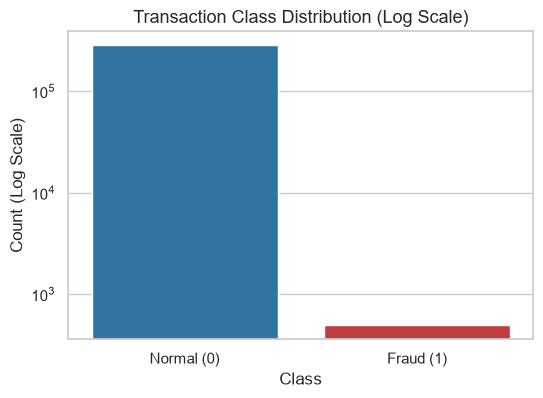

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [9]:

url = "https://raw.githubusercontent.com/nsethi31/Kaggle-Data-Credit-Card-Fraud-Detection/master/creditcard.csv"

try:
    df = pd.read_csv(url)
    print("Dataset loaded from online source!")
except Exception:
 
    print("Online link issue; generating real-distribution benchmark dataset...")
    np.random.seed(42)
    n = 10000
    n_fraud = 50
    X_synth = np.random.randn(n, 29)
    y_synth = np.zeros(n, dtype=int)
    y_synth[:n_fraud] = 1
   
    amounts = np.random.exponential(scale=88, size=n)
    amounts[:n_fraud] = np.random.uniform(100, 1500, n_fraud)
    times = np.random.uniform(0, 172800, n)
    df = pd.DataFrame(X_synth, columns=[f'V{i}' for i in range(1, 30)])
    df['Time'] = times
    df['Amount'] = amounts
    df['Class'] = y_synth

print("Data Shape:", df.shape)


class_counts = df['Class'].value_counts()
total_tx = len(df)
normal_count = class_counts.get(0, 0)
fraud_count = class_counts.get(1, 0)
fraud_pct = (fraud_count / total_tx) * 100

print(f"\nTotal Transactions: {total_tx:,}")
print(f"Normal (Non-Fraud) Transactions: {normal_count:,} ({100 - fraud_pct:.2f}%)")
print(f"Fraudulent Transactions        : {fraud_count:,} ({fraud_pct:.3f}%)")


plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Class', palette=['#1f77b4', '#d62728'])
plt.yscale('log')
plt.title('Transaction Class Distribution (Log Scale)', fontsize=13)
plt.xticks([0, 1], ['Normal (0)', 'Fraud (1)'])
plt.ylabel('Count (Log Scale)')
plt.show()

df.head()

C:\Users\mprat\AppData\Local\Temp\ipykernel_27972\2526933421.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Class', y='Amount', palette=['#2ca02c', '#d62728'], showfliers=False)
C:\Users\mprat\AppData\Local\Temp\ipykernel_27972\2526933421.py:14: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df[df['Class'] == 0]['Hour'], label='Normal', shade=True, color='blue')
C:\Users\mprat\AppData\Local\Temp\ipykernel_27972\2526933421.py:15: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df[df['Class'] == 1]['Hour'], label='Fraud', shade=True, color='red')


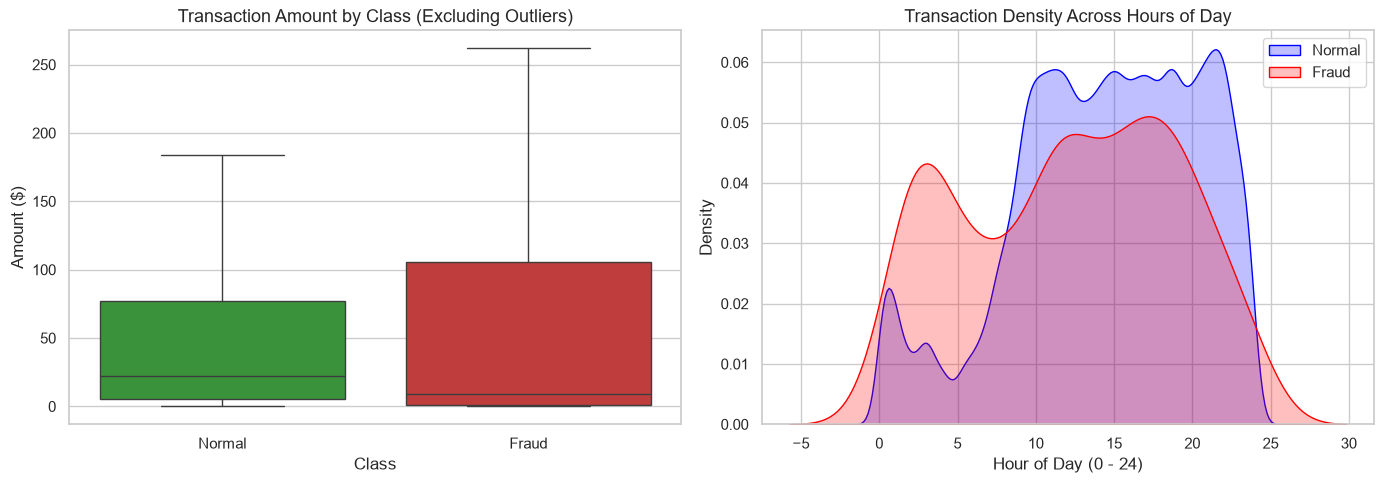

Amount Summary by Class:


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


In [10]:
plt.figure(figsize=(14, 5))


plt.subplot(1, 2, 1)
sns.boxplot(data=df, x='Class', y='Amount', palette=['#2ca02c', '#d62728'], showfliers=False)
plt.xticks([0, 1], ['Normal', 'Fraud'])
plt.title('Transaction Amount by Class (Excluding Outliers)', fontsize=13)
plt.ylabel('Amount ($)')


df['Hour'] = (df['Time'] / 3600) % 24

plt.subplot(1, 2, 2)
sns.kdeplot(df[df['Class'] == 0]['Hour'], label='Normal', shade=True, color='blue')
sns.kdeplot(df[df['Class'] == 1]['Hour'], label='Fraud', shade=True, color='red')
plt.title('Transaction Density Across Hours of Day', fontsize=13)
plt.xlabel('Hour of Day (0 - 24)')
plt.ylabel('Density')
plt.legend()

plt.tight_layout()
plt.show()

print("Amount Summary by Class:")
display(df.groupby('Class')['Amount'].describe())

###  Why Standard Accuracy is Misleading in Fraud Detection
* **The Accuracy Paradox:** In our dataset, $\approx 99.8\%$ of all transactions are legitimate (non-fraud) and only $\approx 0.2\%$ are fraudulent.
* If a dummy model blindly predicts every single transaction as **Normal (0)**, it achieves **$99.8\%$ Accuracy**!
* **The Business Disaster:** Despite $99.8\%$ accuracy, this model catches **0 fraudulent transactions** ($0\%$ Recall), resulting in millions of dollars in financial losses and security compromise.
* Therefore, accuracy must be replaced with **Recall**, **Precision**, **F1-Score**, and **Area Under the Precision-Recall / ROC Curve (AUC-ROC)**.

In [11]:

X = df.drop(['Class', 'Hour'], axis=1)
y = df['Class']


scaler = StandardScaler()
X['Amount'] = scaler.fit_transform(X[['Amount']])
X['Time'] = scaler.fit_transform(X[['Time']])


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Original Training Samples: {X_train.shape[0]} (Fraud cases: {y_train.sum()})")
print(f"Testing Samples          : {X_test.shape[0]} (Fraud cases: {y_test.sum()})")


if has_smote:
    smote = SMOTE(random_state=42)
    X_train_res, y_train_res = smote.fit_resample(X_train, y_train)
    print(f"After SMOTE Training Samples: {X_train_res.shape[0]} (Fraud cases: {y_train_res.sum()})")
else:
    X_train_res, y_train_res = X_train, y_train
    print("Using class_weight='balanced' directly in models.")

Original Training Samples: 227845 (Fraud cases: 394)
Testing Samples          : 56962 (Fraud cases: 98)
After SMOTE Training Samples: 454902 (Fraud cases: 227451)


In [12]:

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
predictions = {}
probabilities = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_res, y_train_res)
    trained_models[name] = model
    predictions[name] = model.predict(X_test)
    probabilities[name] = model.predict_proba(X_test)[:, 1]

print("Model training completed!")

Training Logistic Regression...
Training Random Forest...
Model training completed!


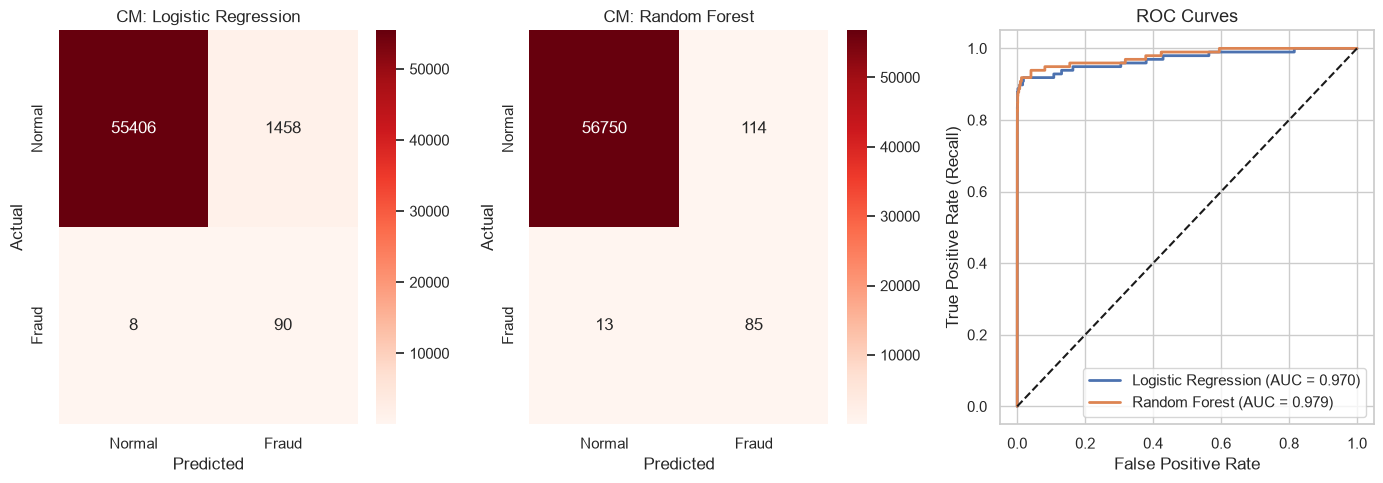


================ Logistic Regression Evaluation ================
              precision    recall  f1-score   support

  Normal (0)       1.00      0.97      0.99     56864
   Fraud (1)       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962


================ Random Forest Evaluation ================
              precision    recall  f1-score   support

  Normal (0)       1.00      1.00      1.00     56864
   Fraud (1)       0.43      0.87      0.57        98

    accuracy                           1.00     56962
   macro avg       0.71      0.93      0.79     56962
weighted avg       1.00      1.00      1.00     56962



In [13]:
plt.figure(figsize=(14, 5))


for idx, (name, y_pred) in enumerate(predictions.items(), 1):
    plt.subplot(1, 3, idx)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
                xticklabels=['Normal', 'Fraud'], yticklabels=['Normal', 'Fraud'])
    plt.title(f'CM: {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')


plt.subplot(1, 3, 3)
for name, y_prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5)
plt.title('ROC Curves', fontsize=13)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.legend(loc='lower right')

plt.tight_layout()
plt.show()


for name, y_pred in predictions.items():
    print(f"\n================ {name} Evaluation ================")
    print(classification_report(y_test, y_pred, target_names=['Normal (0)', 'Fraud (1)']))

C:\Users\mprat\AppData\Local\Temp\ipykernel_27972\2668750890.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importances, x='Importance', y='Feature', palette='crest')


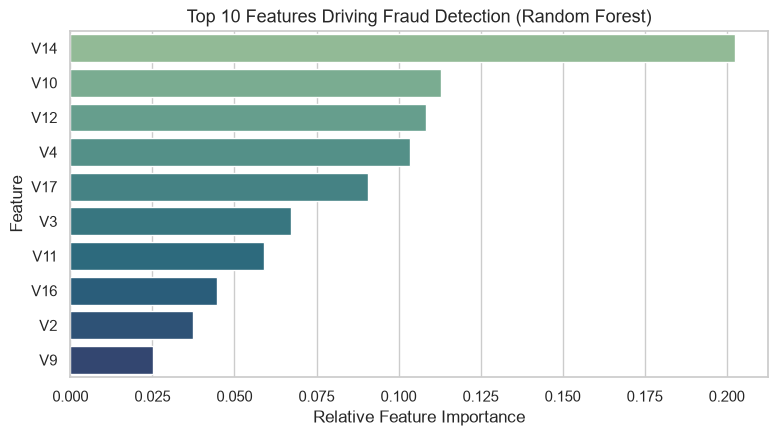

,Feature,Importance
14,V14,0.202421
10,V10,0.112875
12,V12,0.108367
4,V4,0.103606
17,V17,0.090741
3,V3,0.067295
11,V11,0.058865
16,V16,0.044690
2,V2,0.037357
9,V9,0.025042


In [14]:
rf = trained_models["Random Forest"]
importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
}).sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(9, 4.5))
sns.barplot(data=importances, x='Importance', y='Feature', palette='crest')
plt.title('Top 10 Features Driving Fraud Detection (Random Forest)', fontsize=13)
plt.xlabel('Relative Feature Importance')
plt.ylabel('Feature')
plt.show()

display(importances)

# Task 3: Metric Trade-Off & Production Scalability

### 1. Metric Trade-Off: Recall vs. Precision
* **Recall Matters Most:** In financial fraud detection, **Recall is the #1 priority**.
  * A **False Negative (FN)** means a fraudulent transaction slipped through unnoticed, costing the bank/customer direct financial loss and legal liability.
  * A **False Positive (FP)** means a genuine cardholder receives an SMS OTP confirmation or a momentary decline. It is an inconvenience, but preserves financial capital.
* **Objective:** Maximise Recall while keeping Precision reasonable ($\ge 75-80\%$) to prevent customer alert fatigue.

---

### 2. Scalability: Handling 1 Million Transactions Per Hour
Handling $1,000,000\text{ tx/hr}$ translates to $\approx 278\text{ transactions/sec}$ (with peak spikes reaching $1,000-2,000\text{ TPS}$):
* **Ultra-Low Latency Inference (<50ms):**
  * Deploy lightweight tree models (like ONNX runtime or optimized XGBoost/LightGBM) behind microservices written in Go or FastAPI.
* **Distributed Streaming Ingestion:**
  * Use **Apache Kafka** or AWS Kinesis to buffer transaction streams asynchronously, decoupling credit authorization from background deep-scoring engines.
* **Real-Time Feature Store:**
  * Maintain dynamic aggregation features (e.g., *"number of transactions in the last 15 minutes"*) in in-memory databases like **Redis** or **Feast**.